# 03 - Target and incident table

**Goal:** Create one row per incident, containing the target and information available at opening. This notebook addresses four points left open in notebook 02: target definition, initial feature values, incidents without a resolution, and incidents created already `Resolved`.

## 1. Loading

In [24]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # to import src from the notebooks folder

import numpy as np
import pandas as pd
from src import config, data_loading as dl, reconstruction as rc, plots as pl

pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 70)
ID = config.ID_COL
df = dl.load_raw()
n_incidents = df[ID].nunique()
print("rows:", len(df), "| incidents:", n_incidents)

# same numbers as notebooks 01 and 02, otherwise this is not the full event log
assert (len(df), n_incidents) == (141712, 24918)

ev = rc.sort_events(df)

rows: 141712 | incidents: 24918


Events are sorted by `sys_updated_at`, and ties keep the file order (decision of notebook 02). Only one incident has a time going backwards, so the sort changes almost nothing. It matters for the choice of the first event below.

## 2. Target

The target is the time between `opened_at` and the final resolution, in hours. I use `resolved_at`, or the last `Resolved` event if it is empty. Both give the same result when available (notebook 02).

I exclude `closed_at` because it occurs a median of 120 hours after resolution.

The table is built using `build_incident_table` in `src/reconstruction.py`.

In [25]:
table = rc.build_incident_table(df)
target = table[config.TARGET]

assert len(table) == n_incidents and table[ID].is_unique     # one row per incident
assert (target.dropna() >= 0).all()                          # no negative duration

# with resolved_at, the target must be exactly resolved_at - opened_at
ra = df.groupby(ID)["resolved_at"].max().reindex(table[ID]).to_numpy()
hours = (ra - table["opened_at"].to_numpy()) / np.timedelta64(1, "h")
from_ra = table["target_source"].eq("resolved_at").to_numpy()
assert np.allclose(hours[from_ra], target[from_ra])

print(table["target_source"].value_counts().to_string())
target.describe(percentiles=[.5, .9, .99]).round(1).to_frame("resolution_hours").T

target_source
resolved_at            23362
last Resolved event     1543
none                      13


,count,mean,std,min,50%,90%,99%,max
resolution_hours,24905.0,167.3,517.8,0.0,16.1,361.1,2759.9,8070.2


24,905 incidents have a target: 23,362 from `resolved_at` and 1,543 from the last `Resolved` event. The mean (167.3 h) is ten times the median (16.1 h), so a few very long incidents pull the mean up. The skew is studied in the EDA.

## 3. Incidents without a target

An incident that never reaches `Resolved` and has no `resolved_at` has no resolution time. I can't compute a target, so they can't be used by a supervised model.

In [26]:
no_target = table[target.isna()]
(ev[ev[ID].isin(no_target[ID])].groupby(ID, sort=False)
   .agg(n_events=("incident_state", "size"), states=("incident_state", " > ".join),
        opened_at=("opened_at", "first"), closed_code=("closed_code", "first"), priority=("priority", "last")))

,n_events,states,opened_at,closed_code,priority
number,,,,,
INC0003115,2,New > Closed,2016-03-07 09:04:00,code 7,3 - Moderate
INC0005100,3,New > Closed > Closed,2016-03-09 18:35:00,code 1,3 - Moderate
INC0020014,5,New > New > New > Active > Closed,2016-04-16 01:46:00,None,3 - Moderate
INC0119241,2,New > Closed,2017-02-13 06:45:00,code 6,4 - Low
INC0119289,2,New > Closed,2017-02-13 08:56:00,code 6,4 - Low
INC0119392,2,New > Closed,2017-02-13 10:33:00,code 6,4 - Low
INC0119457,2,New > Closed,2017-02-13 11:31:00,code 6,4 - Low
INC0119983,2,New > Closed,2017-02-14 11:11:00,code 6,4 - Low
INC0119987,2,New > Closed,2017-02-14 11:15:00,code 6,4 - Low


There are 13 such incidents (0.05%). None of them pass through the `Resolved` state. Nine are low-priority incidents opened between 13 and 15 February 2017 and closed directly from `New` with `code 6`. This suggests that they are probably routine cases. I keep these incidents in a separate file rather than assigning them an estimated duration. Since they represent only 0.05% of the dataset, their impact is very limited. However, this will still be mentioned as a limitation of the analysis.

## 4. Incidents created already `Resolved`

1,819 incidents have `Resolved` as first event (notebook 02): 1,543 without `resolved_at` and 276 with it. I compare them with the others.

,count,mean,std,min,50%,90%,max,% of incidents
group,,,,,,,,
"created Resolved, has resolved_at",276.0,1.0,9.1,0.0,0.1,0.4,115.8,1.1
"created Resolved, no resolved_at",1543.0,2.4,35.5,0.0,0.0,0.0,600.0,6.2
normal start,23086.0,180.3,535.6,0.0,22.8,383.2,8070.2,92.7


first_event_state,% normal start,% created Resolved
priority,,
1 - Critical,99.5,0.5
2 - High,100.0,0.0
3 - Moderate,92.7,7.3
4 - Low,86.5,13.5


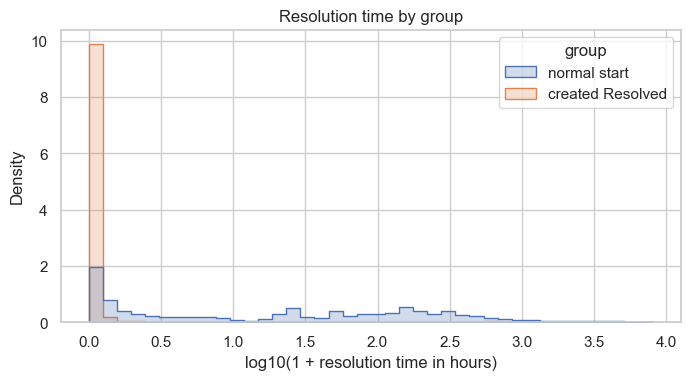

In [27]:
t = table[target.notna()].copy()
t["group"] = np.select(
    [t["first_event_state"].ne("Resolved"), t["target_source"].eq("resolved_at")],
    ["normal start", "created Resolved, has resolved_at"],
    default="created Resolved, no resolved_at")

summary = t.groupby("group")[config.TARGET].describe(percentiles=[.5, .9]).round(1)
summary["% of incidents"] = (summary["count"] / len(t) * 100).round(1)
display(summary)

# is the priority a hint?
created_resolved = t["first_event_state"].eq("Resolved")
display((pd.crosstab(t["priority"], created_resolved, normalize="index") * 100).round(1)
        .rename(columns={False: "% normal start", True: "% created Resolved"}))

pl.plot_target_by_group(t.assign(group=np.where(created_resolved, "created Resolved", "normal start")), "group", config.TARGET);

Incidents created directly in `Resolved` are usually very short, with 90% lasting less than 0.4 hours. Most of them are close to 0 hours, unlike normal incidents.

This occurs more often with low-priority incidents (13.5%), compared with 7.3% for moderate, 0.5% for critical and none for high priority.

I keep these incidents rather than remove 7.3% of the data. A `first_event_state` flag identifies them, and notebooks 05 and 06 will test the models with and without them.


## 5. Reopened incidents and state `-100`

There are 275 reopened incidents. Their target uses the last resolution time stored in `resolved_at`. I keep them and mark them with `reopen_count > 0` for analysis only.

State `-100` appears in only 5 events across 2 incidents:

In [28]:
bad = ev.loc[ev["incident_state"] == "-100", ID].unique()
display(ev[ev[ID].isin(bad)][[ID, "incident_state", "sys_mod_count", "sys_updated_at", "resolved_at", "closed_at"]])
table[table[ID].isin(bad)][[ID, config.TARGET, "target_source"]]

,number,incident_state,sys_mod_count,sys_updated_at,resolved_at,closed_at
115640,INC0028089,New,0,2016-05-10 22:09:00,2016-06-16 13:02:00,2016-06-21 13:07:00
115641,INC0028089,-100,1,2016-06-16 12:02:00,2016-06-16 13:02:00,2016-06-21 13:07:00
115642,INC0028089,-100,2,2016-06-16 12:03:00,2016-06-16 13:02:00,2016-06-21 13:07:00
115643,INC0028089,Resolved,3,2016-06-16 12:03:00,2016-06-16 13:02:00,2016-06-21 13:07:00
115644,INC0028089,Resolved,4,2016-06-16 13:02:00,2016-06-16 13:02:00,2016-06-21 13:07:00
115645,INC0028089,Closed,5,2016-06-21 13:07:00,2016-06-16 13:02:00,2016-06-21 13:07:00
124503,INC0030413,New,0,2016-05-17 14:45:00,2016-06-21 17:28:00,2016-06-26 18:00:00
124504,INC0030413,New,1,2016-05-17 14:46:00,2016-06-21 17:28:00,2016-06-26 18:00:00
124505,INC0030413,Active,11,2016-06-15 17:05:00,2016-06-21 17:28:00,2016-06-26 18:00:00
124506,INC0030413,Active,13,2016-06-15 17:13:00,2016-06-21 17:28:00,2016-06-26 18:00:00


,number,resolution_hours,target_source
19908,INC0028089,878.883333,resolved_at
21665,INC0030413,842.766667,resolved_at


In both incidents `-100` comes just before `Resolved`, so it looks like a wrong label for a step of the closing process. The target only uses `Resolved` and `resolved_at`, so it is not affected (879 h and 843 h). The state is never a feature. I keep both incidents.

## 6. Initial feature values

Features can change during an incident, so using the last event may introduce future information. I use the value from the **first event** and never fill missing values from later events. The first event is close to opening (median: 1 minute, notebook 02), making it a good representation of the initial state.

In [29]:
first = ev.groupby(ID, sort=False).head(1).set_index(ID)
last = ev.groupby(ID, sort=False).tail(1).set_index(ID)

lag_h = (first["sys_updated_at"] - first["opened_at"]).dt.total_seconds() / 3600
print("first event more than 1 hour after opened_at:", int((lag_h > 1).sum()))
print("first event before opened_at:", int((lag_h < 0).sum()))

# where does the first value differ from the last one? and is an empty first value filled later?
rows = []
for c in config.INITIAL_COLS:
    changed = ~((first[c] == last[c]) | (first[c].isna() & last[c].isna()))
    filled_later = first[c].isna() & ev[c].notna().groupby(ev[ID]).any().reindex(first.index)
    rows.append({"column": c, "first != last": int(changed.sum()), "%": round(changed.mean() * 100, 1),
                 "empty at first, filled later": int(filled_later.sum())})
pd.DataFrame(rows).set_index("column")

first event more than 1 hour after opened_at: 159
first event before opened_at: 5


,first != last,%,"empty at first, filled later"
column,,,
caller_id,2,0.0,0
opened_by,0,0.0,0
sys_created_by,0,0.0,0
contact_type,5,0.0,0
location,107,0.4,46
category,1185,4.8,32
subcategory,1764,7.1,61
u_symptom,1770,7.1,222
impact,292,1.2,0


For 159 incidents (0.6%), the first event occurs more than one hour after opening, making it a good proxy for the initial state.

`assignment_group` changes the most (40.7% of incidents). Other columns, such as `category`, `subcategory` and `u_symptom`, change less frequently. Values added later are left empty to avoid future information.

`cmdb_ci` and `sys_created_at` are excluded due to low usefulness. `sys_created_by` remains a candidate despite 46.1% missing values. Columns describing incident progress, such as `state`, `assigned_to` and closure fields, are also excluded.

## 7. Checks and saving

In [30]:
model_table = table[target.notna()].reset_index(drop=True)

# every column is in exactly one group
groups = {
    "key": [ID],
    "target": [config.TARGET],
    "features at opening": ["opened_at"] + config.INITIAL_COLS,
    "analysis only": config.ANALYSIS_ONLY_COLS,
}
listed = sum(groups.values(), [])
assert sorted(listed) == sorted(model_table.columns) and len(listed) == len(set(listed))

# recompute 100 incidents one by one and compare with the table
rng = np.random.default_rng(config.RANDOM_STATE)
for num in rng.choice(model_table[ID], 100, replace=False):
    e = df[df[ID] == num].sort_values("sys_updated_at", kind="stable")
    row = model_table[model_table[ID] == num].iloc[0]
    for c in config.INITIAL_COLS + ["opened_at"]:
        assert (pd.isna(e[c].iloc[0]) and pd.isna(row[c])) or e[c].iloc[0] == row[c], (num, c)

config.DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
config.DATA_INTERIM_DIR.mkdir(parents=True, exist_ok=True)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
date_fmt = "%Y-%m-%d %H:%M:%S"
model_table.to_csv(config.INCIDENT_FILE, index=False, date_format=date_fmt)
no_target.to_csv(config.NO_TARGET_FILE, index=False, date_format=date_fmt)

counts = pd.Series({
    "incidents in the event log": n_incidents,
    "excluded: no resolution time": len(no_target),
    "kept for the models": len(model_table),
    "  of which created already Resolved": int((model_table["first_event_state"] == "Resolved").sum()),
    "  of which reopened": int((model_table["reopen_count"] > 0).sum()),
}, name="n_incidents").to_frame()
counts["%"] = (counts["n_incidents"] / n_incidents * 100).round(2)
counts.to_csv(config.TABLES_DIR / "incident_table_summary.csv")
print("saved:", config.INCIDENT_FILE.relative_to(config.PROJECT_ROOT), model_table.shape)
counts

saved: data\processed\incident_table.csv (24905, 22)


,n_incidents,%
incidents in the event log,24918,100.00
excluded: no resolution time,13,0.05
kept for the models,24905,99.95
of which created already Resolved,1819,7.30
of which reopened,275,1.10


The table contains 24,905 incidents and 22 columns. Some columns (`target_source`, `first_event_state`, `n_events`, `reassignment_count`, `reopen_count` and `closed_at`) describe events after opening. They are used only for EDA and error analysis, not for the main model.

**Decisions**

- **Target:** Time between `opened_at` and the final resolution, in hours (`resolved_at` or the last `Resolved` event).
- The 13 incidents never reaching `Resolved` are excluded and saved in `data/interim/incidents_without_target.csv`.
- Incidents created already `Resolved` (1,819) and reopened incidents (275) are kept with a flag. The first group will be tested with and without in notebooks 05–06.
- State `-100`: no impact on the target; both incidents are kept.
- Features use the first event value. Missing values are never filled using later events.
- `cmdb_ci` and `sys_created_at` are excluded. `sys_created_by` is checked during EDA.
- **Output:** `data/processed/incident_table.csv` (24,905 rows).